# Chapitre 1 - Exercices 1.6 à 1.10

Ces exercices portent sur la seconde moitié du chapitre (sections *Planning AI
Applications* et *The AI Engineering Stack*) : chiffrer, décider, planifier.

- **1.6** : coût mensuel d'un chatbot multi-tours (et pourquoi l'historique coûte cher) ;
- **1.7** : marge et latence d'une application par abonnement (utilisateurs intensifs,
  choix du modèle) ;
- **1.8** : grille de décision « faut-il construire cette application d'IA ? », avec
  analyse de robustesse aux pondérations ;
- **1.9** : planifier les jalons : extrapoler une courbe de qualité et organiser le passage
  *Crawl-Walk-Run* ;
- **1.10** : construire ou acheter quand les prix des API baissent.

Tous les tarifs utilisés sont **hypothétiques** (ordres de grandeur 2024-2025) : l'objectif
est la méthode, pas les chiffres d'un fournisseur.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie.plotting import INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, annotate_bars, finish
from aie import ch01_introduction as c1

c1.setup_style()
rng = np.random.default_rng(0)

PRICES = {"petit modèle": (0.15, 0.60), "grand modèle": (2.50, 10.00)}   # $ / M tokens (entrée, sortie)

## Exercice 1.6 : Coût mensuel d'un chatbot multi-tours

**Énoncé.** Un assureur déploie un chatbot de support. Hypothèses : 20 000 conversations
par jour, 4 tours par conversation en moyenne ; prompt système de 800 tokens ; à chaque
tour, 600 tokens de contexte récupéré (RAG), une question de 60 tokens et une réponse de
180 tokens. Comme l'API est sans état, **tout l'historique** est renvoyé à chaque tour.

1. Établir le nombre de tokens d'entrée et de sortie par conversation en fonction du
   nombre de tours $T$.
2. Calculer le coût mensuel (30 jours) avec le petit et le grand modèle de la table
   `PRICES`. Quelle part vient des tokens d'entrée ?
3. Tracer le coût mensuel en fonction de $T$ (1 à 15). Que se passe-t-il si les
   utilisateurs dialoguent plus longtemps ? Proposer deux leviers de réduction.

**Rappels.** Section *Setting Expectations* : le coût par requête fait partie du seuil
d'utilité. Coût d'une requête : $(n_{\text{in}} p_{\text{in}} + n_{\text{out}} p_{\text{out}})/10^6$
(cours 3, section 5).

**Solution.**

*1.* Notons $S = 800$, $C = 600$, $q = 60$, $a = 180$. Au tour $t$, l'entrée contient
$S + C + q$ plus l'historique des $t-1$ tours précédents, soit $(t-1)(q+a)$. En sommant :
$$n_{\text{in}}(T) = T\,(S + C + q) + (q + a)\,\frac{T(T-1)}{2}, \qquad n_{\text{out}}(T) = T\,a.$$
Pour $T = 4$ : $n_{\text{in}} = 4 \times 1\,460 + 240 \times 6 = 7\,280$ et
$n_{\text{out}} = 720$.

*2.* Coût d'une conversation au petit modèle :
$(7\,280 \times 0{,}15 + 720 \times 0{,}60)/10^6 \approx 0{,}0015$ $, soit
$\times 20\,000 \times 30 \approx 914$ $ par mois. Au grand modèle :
$(7\,280 \times 2{,}5 + 720 \times 10)/10^6 \approx 0{,}0254$ $, soit environ 15 200 $ par
mois, plus de 16 fois plus.

In [2]:
S, C, q, a = 800, 600, 60, 180
n_in, n_out = c1.conversation_tokens(4, S, C, q, a)
rows = []
for name, (pin, pout) in PRICES.items():
    per_conv = c1.request_cost(n_in, n_out, pin, pout)
    rows.append({"modèle": name, "tokens entrée / conv.": n_in, "tokens sortie / conv.": n_out,
                 "coût / conversation ($)": round(per_conv, 5), "coût mensuel ($)": round(per_conv * 20_000 * 30),
                 "part de l'entrée": f"{n_in * pin / (n_in * pin + n_out * pout):.0%}"})
pd.DataFrame(rows).set_index("modèle")

,tokens entrée / conv.,tokens sortie / conv.,coût / conversation ($),coût mensuel ($),part de l'entrée
modèle,,,,,
petit modèle,7280,720,0.00152,914,72%
grand modèle,7280,720,0.02540,15240,72%


Les tokens d'entrée représentent environ 70 % de la facture, alors que chaque token
d'entrée est 4 fois moins cher qu'un token de sortie : c'est l'effet du prompt système, du
contexte RAG et de l'historique, renvoyés à chaque tour.

*3.* Le terme en $T(T-1)/2$ rend le coût **quadratique** en nombre de tours.

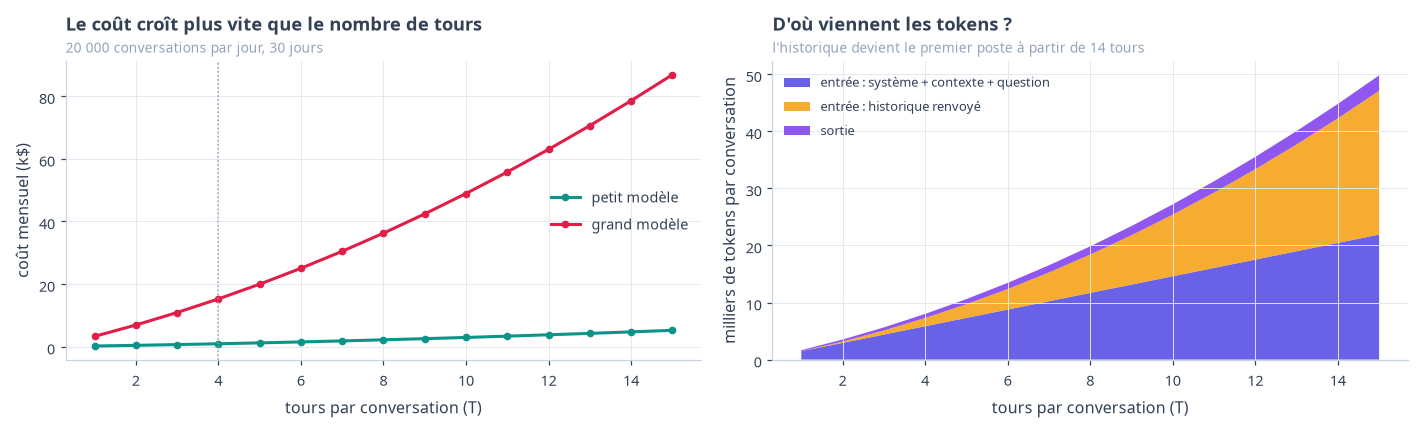

In [3]:
Ts = np.arange(1, 16)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (name, (pin, pout)), col in zip(PRICES.items(), [TEAL, ROSE]):
    cost = [c1.request_cost(*c1.conversation_tokens(T, S, C, q, a), pin, pout) * 20_000 * 30 for T in Ts]
    axes[0].plot(Ts, np.array(cost) / 1000, "o-", color=col, label=name, ms=4)
axes[0].axvline(4, color=GRAY, ls=":", lw=1)
axes[0].set_xlabel("tours par conversation (T)"); axes[0].set_ylabel("coût mensuel (k$)")
axes[0].legend()
c1.title_sub(axes[0], "Le coût croît plus vite que le nombre de tours", "20 000 conversations par jour, 30 jours")
parts = np.array([[T * (S + C + q), (q + a) * T * (T - 1) / 2, T * a] for T in Ts])
axes[1].stackplot(Ts, parts.T / 1000, colors=[INDIGO, AMBER, VIOLET],
                  labels=["entrée : système + contexte + question", "entrée : historique renvoyé", "sortie"], alpha=0.85)
axes[1].set_xlabel("tours par conversation (T)"); axes[1].set_ylabel("milliers de tokens par conversation")
axes[1].legend(loc="upper left", fontsize=8.5)
c1.title_sub(axes[1], "D'où viennent les tokens ?", "l'historique devient le premier poste à partir de 14 tours")
finish(fig); plt.show()

Si les conversations passent de 4 à 12 tours, le coût est multiplié par plus de 4 (et non
par 3). Deux leviers classiques : **résumer ou tronquer l'historique** au-delà de quelques
tours (gestion de la mémoire, chapitre 6), et profiter de la **mise en cache du préfixe**
(prompt système et historique identiques d'un tour à l'autre) que proposent de nombreux
fournisseurs à prix réduit (chapitre 9). Choisir le petit modèle pour les demandes simples
(routage) est un troisième levier. $\blacksquare$

> **À retenir.** Dans une application conversationnelle, l'entrée domine la facture : prompt
> système, contexte et historique sont renvoyés à chaque tour, d'où un coût quadratique en
> nombre de tours.

## Exercice 1.7 : Marge et latence d'une application par abonnement

**Énoncé.** Un assistant d'écriture est vendu 20 $ par mois et par utilisateur. Chaque
requête consomme 1 500 tokens d'entrée et 400 de sortie. L'usage est très inégal : le
nombre de requêtes par jour d'un utilisateur suit une loi log-normale de médiane 10 et de
paramètre $\sigma = 1$.

1. Calculer le coût mensuel d'un utilisateur médian pour chaque modèle, et le seuil
   d'usage (requêtes/jour) au-delà duquel un utilisateur devient non rentable.
2. Par simulation (10 000 utilisateurs), estimer la marge brute globale et la part
   d'utilisateurs non rentables pour chaque modèle.
3. Latence : le petit modèle a un TTFT de 0,2 s et un TPOT de 8 ms ; le grand, 0,5 s et
   25 ms. Calculer la latence d'une réponse complète. Quel compromis proposer ?

**Rappels.** Sections *Setting Expectations* (coût, latence) et *AI product defensibility*
(une application bâtie sur un modèle tiers dépend de ses prix). Latence totale
$= \text{TTFT} + (n - 1)\,\text{TPOT}$. Si $\ln X \sim \mathcal N(\mu, \sigma^2)$, la médiane
de $X$ est $e^{\mu}$ et $P(X > x) = 1 - \Phi\big((\ln x - \mu)/\sigma\big)$.

**Solution.**

*1.* Coût d'une requête : petit modèle $(1\,500 \times 0{,}15 + 400 \times 0{,}6)/10^6 =
0{,}000465$ $ ; grand modèle $(1\,500 \times 2{,}5 + 400 \times 10)/10^6 = 0{,}00775$ $.
Utilisateur médian (10 requêtes/jour, 300 par mois) : 0,14 $ et 2,33 $. Seuil de
rentabilité : $20 / (30 \times \text{coût})$, soit environ 1 430 requêtes/jour au petit
modèle (jamais atteint en pratique) et **86 requêtes/jour** au grand modèle. Avec
$\mu = \ln 10$ et $\sigma = 1$ : $P(X > 86) = 1 - \Phi(\ln 8{,}6) = 1 - \Phi(2{,}15) \approx
1{,}6\,\%$ des utilisateurs.

In [4]:
from math import erf, log, sqrt
cost_req = {k: c1.request_cost(1500, 400, *p) for k, p in PRICES.items()}
for k, c in cost_req.items():
    thr = 20 / (30 * c)
    p_unprof = 0.5 * (1 - erf((log(thr) - log(10)) / sqrt(2)))
    print(f"{k:13s} coût/requête {c:.6f} $ | médian {300 * c:5.2f} $/mois | seuil {thr:6.0f} req/jour | "
          f"P(non rentable) théorique {p_unprof:.2%}")

petit modèle  coût/requête 0.000465 $ | médian  0.14 $/mois | seuil   1434 req/jour | P(non rentable) théorique 0.00%
grand modèle  coût/requête 0.007750 $ | médian  2.33 $/mois | seuil     86 req/jour | P(non rentable) théorique 1.57%


*2.* Simulation :

In [5]:
usage = rng.lognormal(mean=np.log(10), sigma=1.0, size=10_000)        # requêtes / jour
rows = []
for k, c in cost_req.items():
    cost_user = usage * 30 * c
    rows.append({"modèle": k, "marge brute globale": f"{1 - cost_user.sum() / (20 * len(usage)):.1%}",
                 "utilisateurs non rentables": f"{np.mean(cost_user > 20):.2%}",
                 "coût du 1 % le plus intensif / coût total": f"{np.sort(cost_user)[-100:].sum() / cost_user.sum():.0%}"})
pd.DataFrame(rows).set_index("modèle")

,marge brute globale,utilisateurs non rentables,coût du 1 % le plus intensif / coût total
modèle,,,
petit modèle,98.9%,0.00%,8%
grand modèle,80.9%,1.56%,8%


Même avec le grand modèle, la marge globale reste confortable (autour de 80 %), mais une
petite fraction d'utilisateurs intensifs coûte plus qu'elle ne rapporte, et le 1 % le plus
actif pèse à lui seul environ 8 % des coûts (huit fois son poids dans la base) : d'où les
quotas, ou les offres différenciées.

*3.* Latence d'une réponse de 400 tokens : petit modèle $0{,}2 + 399 \times 0{,}008 \approx
3{,}4$ s ; grand modèle $0{,}5 + 399 \times 0{,}025 \approx 10{,}5$ s. En **streamant** la
réponse, la latence perçue se rapproche du TTFT. Compromis raisonnable : petit modèle par
défaut (marge ≈ 99 %, réponse en ~3 s), grand modèle réservé aux demandes difficiles ou à
une offre premium, et un quota pour les usages extrêmes. $\blacksquare$

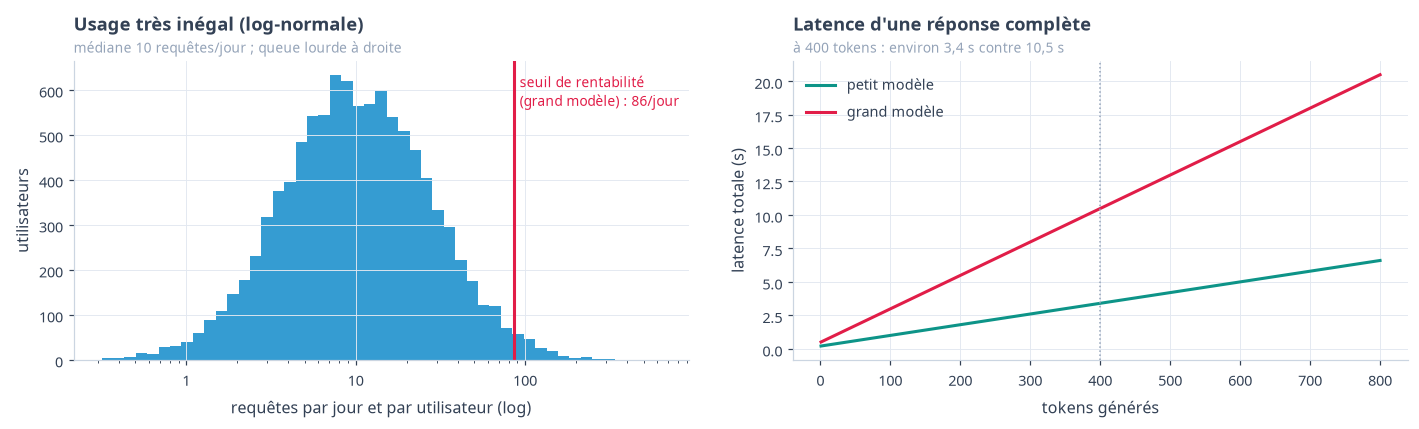

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.logspace(-0.5, 2.8, 50)
axes[0].hist(usage, bins=bins, color=SKY, alpha=0.8)
for k, col in zip(cost_req, [TEAL, ROSE]):
    thr = 20 / (30 * cost_req[k])
    if thr < bins[-1]:
        axes[0].axvline(thr, color=col, lw=2)
        axes[0].text(thr * 1.08, axes[0].get_ylim()[1] * 0.85, f"seuil de rentabilité\n({k}) : {thr:.0f}/jour", color=col, fontsize=9)
axes[0].set_xscale("log"); c1.plain_log(axes[0], "x")
axes[0].set_xlabel("requêtes par jour et par utilisateur (log)"); axes[0].set_ylabel("utilisateurs")
c1.title_sub(axes[0], "Usage très inégal (log-normale)", "médiane 10 requêtes/jour ; queue lourde à droite")
n = np.arange(1, 801)
for (k, ttft, tpot), col in zip([("petit modèle", 0.2, 0.008), ("grand modèle", 0.5, 0.025)], [TEAL, ROSE]):
    axes[1].plot(n, c1.generation_latency(n, ttft, tpot), color=col, label=k)
axes[1].axvline(400, color=GRAY, ls=":", lw=1)
axes[1].set_xlabel("tokens générés"); axes[1].set_ylabel("latence totale (s)")
axes[1].legend()
c1.title_sub(axes[1], "Latence d'une réponse complète", "à 400 tokens : environ 3,4 s contre 10,5 s")
finish(fig); plt.show()

> **À retenir.** Le coût moyen ne suffit pas : avec des usages à queue lourde, il faut
> raisonner par distribution (utilisateurs non rentables, quotas). Coût et latence plaident
> souvent pour un petit modèle par défaut, le grand étant réservé aux cas qui le justifient.

## Exercice 1.8 : Grille de décision « faut-il construire cette application d'IA ? »

**Énoncé.** On note cinq projets de 0 à 3 sur les critères de `c1.DECISION_CRITERIA`
(tirés des sections *Use Case Evaluation*, *The role of AI and humans*, *AI product
defensibility* et *Maintenance*), pondérés par `c1.DEFAULT_WEIGHTS`.

1. Justifier les notes proposées ci-dessous pour au moins deux projets, calculer le score
   (0 à 100) et le verdict de chaque projet.
2. Les pondérations sont subjectives. Tirer 2 000 jeux de poids aléatoires (loi de
   Dirichlet centrée sur les poids par défaut) et mesurer la stabilité des verdicts.
3. Quelles limites voyez-vous à une telle grille ?

**Rappels.** Le livre recommande de se demander pourquoi construire (menace, opportunité,
exploration), quel rôle donner à l'IA et à l'humain, comment se défendre, et d'anticiper
les risques réglementaires (cours 3, sections 3, 4 et 7).

In [7]:
pd.Series(c1.DECISION_CRITERIA, name="question").to_frame().assign(poids=pd.Series(c1.DEFAULT_WEIGHTS))

,question,poids
enjeu,pourquoi construire ? (3 = menace existentiell...,2
tolerance_erreurs,l'application tolère-t-elle les erreurs ? (IA ...,2
evaluabilite,peut-on mesurer objectivement la qualité ? (tâ...,2
capacite_modele,les modèles actuels sont-ils proches du seuil ...,3
valeur_vs_cout,le gain attendu dépasse-t-il nettement le coût...,3
defendabilite,"avantage durable : données propriétaires, dist...",1
risque_reglementaire,faible exposition réglementaire / propriété in...,2


**Solution.**

*1.* Notes proposées et justification de deux projets :

- **Résumé interne de réunions** : enjeu faible (1, gain de productivité), forte tolérance
  aux erreurs (3 : un humain relit, l'IA est complémentaire), évaluabilité moyenne (2),
  capacité des modèles excellente (3), valeur réelle mais modeste (2), peu défendable (1 :
  c'est une fonctionnalité des suites bureautiques), risque réglementaire faible (3).
- **Diagnostic radiologique autonome** : enjeu élevé (2), aucune tolérance à l'erreur (0 :
  IA critique, sans humain), évaluabilité correcte (2 : vérité terrain disponible),
  capacité des modèles généralistes insuffisante (1), valeur potentielle forte (3),
  défendabilité par les données (2), risque réglementaire maximal (0 : dispositif médical).

In [8]:
projects = {
    "Chatbot support (assureur)":      dict(enjeu=2, tolerance_erreurs=1, evaluabilite=1, capacite_modele=2, valeur_vs_cout=3, defendabilite=2, risque_reglementaire=1),
    "Résumé interne de réunions":      dict(enjeu=1, tolerance_erreurs=3, evaluabilite=2, capacite_modele=3, valeur_vs_cout=2, defendabilite=1, risque_reglementaire=3),
    "Diagnostic radiologique autonome": dict(enjeu=2, tolerance_erreurs=0, evaluabilite=2, capacite_modele=1, valeur_vs_cout=3, defendabilite=2, risque_reglementaire=0),
    "Startup « analyse de PDF » (API)": dict(enjeu=1, tolerance_erreurs=2, evaluabilite=2, capacite_modele=3, valeur_vs_cout=1, defendabilite=0, risque_reglementaire=2),
    "Extraction de factures (interne)": dict(enjeu=2, tolerance_erreurs=2, evaluabilite=3, capacite_modele=3, valeur_vs_cout=3, defendabilite=1, risque_reglementaire=2),
}
grid = pd.DataFrame(projects).T[list(c1.DEFAULT_WEIGHTS)]
grid["score"] = [c1.decision_score(p) for p in projects.values()]
grid["verdict"] = [c1.decision_verdict(sc, p) for sc, p in zip(grid["score"], projects.values())]
grid.round(1)

,enjeu,tolerance_erreurs,evaluabilite,capacite_modele,valeur_vs_cout,defendabilite,risque_reglementaire,score,verdict
Chatbot support (assureur),2,1,1,2,3,2,1,60.0,"prototype limité, puis réévaluer"
Résumé interne de réunions,1,3,2,3,2,1,3,75.6,construire
Diagnostic radiologique autonome,2,0,2,1,3,2,0,48.9,ne pas construire pour l'instant
Startup « analyse de PDF » (API),1,2,2,3,1,0,2,57.8,"prototype limité, puis réévaluer"
Extraction de factures (interne),2,2,3,3,3,1,2,82.2,construire


L'extraction de factures interne (évaluable, à forte valeur, bien maîtrisée par les
modèles actuels) arrive en tête ; le diagnostic autonome est pénalisé par l'absence de
tolérance aux erreurs et le risque réglementaire ; la startup d'analyse de PDF, sans
défendabilité, illustre l'avertissement du livre sur les produits qui pourraient n'être
qu'une fonctionnalité d'un modèle ou d'une suite logicielle.

*2.* Robustesse aux pondérations : on tire $w \sim \text{Dirichlet}(\alpha)$ avec
$\alpha = 35\, w_0 / \lVert w_0 \rVert_1$ (7 critères × 5), c'est-à-dire des poids aléatoires
dont la moyenne est proportionnelle aux poids par défaut $w_0$, avec une dispersion
notable, et on recalcule les scores.

In [9]:
w0 = np.array(list(c1.DEFAULT_WEIGHTS.values()), dtype=float)
alpha = 5 * len(w0) * w0 / w0.sum()
W = rng.dirichlet(alpha, size=2000)
keys = list(c1.DEFAULT_WEIGHTS)
sim = {name: [c1.decision_score(p, dict(zip(keys, w))) for w in W] for name, p in projects.items()}
stab = pd.DataFrame({name: {"score médian": np.median(v), "intervalle 5-95 %": f"{np.percentile(v, 5):.0f} - {np.percentile(v, 95):.0f}",
                            "part « construire »": f"{np.mean([c1.decision_verdict(x, projects[name]) == 'construire' for x in v]):.0%}"}
                     for name, v in sim.items()}).T
stab

,score médian,intervalle 5-95 %,part « construire »
Chatbot support (assureur),60.040448,53 - 67,1%
Résumé interne de réunions,75.588418,68 - 82,90%
Diagnostic radiologique autonome,49.048379,39 - 59,0%
Startup « analyse de PDF » (API),57.697479,50 - 65,0%
Extraction de factures (interne),82.4475,76 - 88,100%


**Vérification graphique.**

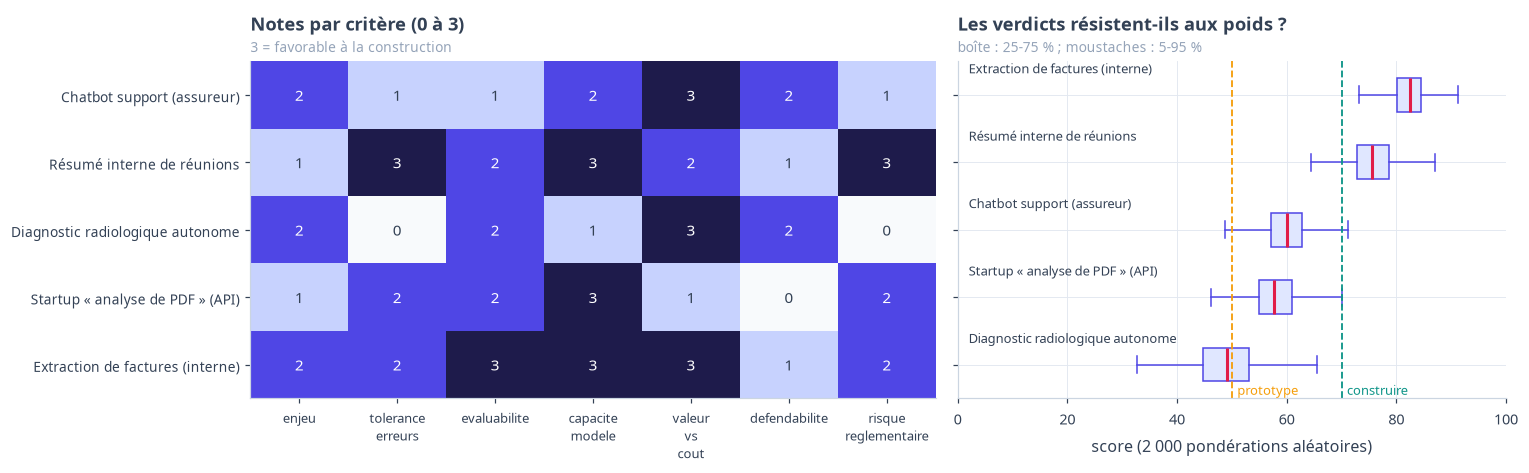

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
crit = grid[keys].astype(float)
im = axes[0].imshow(crit.values, cmap="aie_seq", vmin=0, vmax=3, aspect="auto")
axes[0].set_xticks(range(len(keys)), [k.replace("_", "\n") for k in keys], fontsize=8.5)
axes[0].set_yticks(range(len(crit)), crit.index, fontsize=9)
axes[0].grid(False)
for i in range(crit.shape[0]):
    for j in range(crit.shape[1]):
        axes[0].text(j, i, f"{crit.values[i, j]:.0f}", ha="center", va="center", color="white" if crit.values[i, j] >= 2 else SLATE)
c1.title_sub(axes[0], "Notes par critère (0 à 3)", "3 = favorable à la construction")
order = grid["score"].sort_values().index
axes[1].boxplot([sim[n] for n in order], orientation="horizontal", widths=0.5, patch_artist=True,
                boxprops=dict(facecolor=LIGHT[INDIGO], edgecolor=INDIGO), medianprops=dict(color=ROSE, lw=2),
                whiskerprops=dict(color=INDIGO), capprops=dict(color=INDIGO), showfliers=False)
axes[1].set_yticks(range(1, len(order) + 1), [""] * len(order))
for i, n in enumerate(order):
    axes[1].text(2, i + 1.32, n, fontsize=8.5, color=SLATE)
for x_, lab, col in [(50, "prototype", AMBER), (70, "construire", TEAL)]:
    axes[1].axvline(x_, color=col, ls="--", lw=1.2)
    axes[1].text(x_ + 1, 0.55, lab, color=col, fontsize=8.5)
axes[1].set_xlim(0, 100); axes[1].set_xlabel("score (2 000 pondérations aléatoires)")
c1.title_sub(axes[1], "Les verdicts résistent-ils aux poids ?", "boîte : 25-75 % ; moustaches : 5-95 %")
finish(fig); plt.show()

Les verdicts extrêmes sont stables : l'extraction de factures est « à construire » pour
presque tous les jeux de poids, le diagnostic autonome jamais. Le résumé de réunions est
« à construire » dans la grande majorité des tirages, mais pas tous. Le chatbot de
l'assureur et la startup PDF restent dans la zone « prototype », avec des intervalles qui
se chevauchent largement : leur classement relatif dépend des pondérations, donc de
**jugements de valeur** qu'il faut expliciter et discuter (que pèse la défendabilité face
au risque réglementaire ?).

*3.* Limites : les notes sont subjectives et souvent mal calibrées ; les critères ne sont
pas indépendants (la tolérance aux erreurs et le risque réglementaire sont corrélés) ; une
somme pondérée laisse compenser un défaut rédhibitoire par des qualités (d'où le **veto**
sur la capacité du modèle et la valeur dans `decision_verdict`) ; enfin, la meilleure
façon de noter la capacité du modèle est... de **l'évaluer** sur des exemples réels
(chapitres 3 et 4). La grille structure la discussion ; elle ne remplace pas le prototype.
$\blacksquare$

> **À retenir.** Une grille de décision rend explicites les questions du livre (enjeu, rôle
> de l'IA, défendabilité, risques). Testez sa robustesse aux pondérations : seuls les
> verdicts stables sont des conclusions, les autres sont des débats à mener.